# Module 14 — Exercises — Solutions

These exercises follow the order of the concept guide: entropy, cross-entropy and KL, joint and conditional
entropy, Huffman coding, KL between Gaussians, information gain, perplexity and temperature, two conceptual
questions, the ELBO, and finally a mini-project that builds a character-level language model and measures it
in bits. Unless an exercise says otherwise, work in **bits** (base-2 logarithms). Several checks compare your
answer against a *hidden* value, so compute carefully rather than guessing.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import heapq, itertools
from scipy.stats import norm
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)
LN2 = np.log(2)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Entropy, with zeros handled correctly  `★☆☆`

Implement `entropy(p, base=2)` for a discrete distribution given as a list or NumPy array of probabilities,
returning a **float** in the units of `base` (bits for 2, nats for `np.e`). Use only NumPy. Entries equal to
0 must contribute 0 (the convention $0\log 0 = 0$) — your function must not return `nan` or raise a warning
for them. Do not use `scipy.stats.entropy` inside your implementation (the check uses it as a reference).

In [3]:
def entropy(p, base=2):
    p = np.asarray(p, dtype=float).ravel()
    p = p[p > 0]                       # 0 log 0 = 0
    return float(-np.sum(p * np.log(p)) / np.log(base))

**Check your answer:**

In [4]:
from scipy.stats import entropy as _sp_entropy
try:
    got = entropy([0.5, 0.5])
except Exception:
    got = None
check_close('fair coin has 1 bit', got, 1.0)
try:
    got = entropy(np.full(6, 1/6))
except Exception:
    got = None
check_close('fair die has log2 6 bits', got, np.log2(6))
try:
    got = entropy([0.9, 0.1], base=np.e)
except Exception:
    got = None
check_close('nats agree with scipy.stats.entropy', got, _sp_entropy([0.9, 0.1]))
try:
    got = entropy([0.1, 0.2, 0.3, 0.4])
except Exception:
    got = None
check_hash('hidden: entropy of (0.1, 0.2, 0.3, 0.4) in bits', got, '5c5724e859b6611e')
try:
    got = entropy([0.5, 0.2, 0.2, 0.1, 0.0])
except Exception:
    got = None
check_hash('hidden: a distribution with a zero entry', got, '41eb44952e67430a')
try:
    got = entropy([1.0, 0.0, 0.0])
except Exception:
    got = None
check_close('a certain outcome has zero entropy', got, 0.0)

✅ fair coin has 1 bit
✅ fair die has log2 6 bits
✅ nats agree with scipy.stats.entropy
✅ hidden: entropy of (0.1, 0.2, 0.3, 0.4) in bits
✅ hidden: a distribution with a zero entry
✅ a certain outcome has zero entropy


True

**Why this works**

Dropping the zero entries before taking logarithms implements $0\log 0 = 0$ without producing `nan`
(`0 * np.log(0)` is `nan` in NumPy, and `np.log(0)` emits a warning). Dividing by $\log(\text{base})$
converts from nats to any unit, since $\log_b u = \ln u / \ln b$. The common wrong turn is to use
`np.where(p > 0, p * np.log(p), 0)`, which still evaluates `np.log(0)` for the masked entries and warns;
masking first is cleaner. A certain outcome gives exactly 0 and a uniform distribution over $n$ outcomes gives
$\log_2 n$, the two extremes of the entropy.

## Exercise 2 — Cross-entropy and KL divergence with their edge cases  `★☆☆`

Implement, in **bits**, using only NumPy:

* `kl_divergence(p, q)` $= \sum_x p(x)\log_2\frac{p(x)}{q(x)}$;
* `cross_entropy(p, q)` $= -\sum_x p(x)\log_2 q(x)$.

Both take arrays of the same length and return a **float**. Conventions: a term with $p(x) = 0$ contributes
0 whatever $q(x)$ is; if some $x$ has $p(x) > 0$ and $q(x) = 0$ the result is `float('inf')` (not `nan`,
no exception). The checks use $p = (0.7, 0.2, 0.1)$, $q = (0.5, 0.3, 0.2)$ and some edge cases.

In [5]:
def kl_divergence(p, q):
    p, q = np.asarray(p, dtype=float).ravel(), np.asarray(q, dtype=float).ravel()
    mask = p > 0
    if np.any(q[mask] == 0):
        return float('inf')
    return float(np.sum(p[mask] * np.log2(p[mask] / q[mask])))

def cross_entropy(p, q):
    p, q = np.asarray(p, dtype=float).ravel(), np.asarray(q, dtype=float).ravel()
    mask = p > 0
    if np.any(q[mask] == 0):
        return float('inf')
    return float(-np.sum(p[mask] * np.log2(q[mask])))

**Check your answer:**

In [6]:
from scipy.stats import entropy as _sp_entropy
p_ = np.array([0.7, 0.2, 0.1]); q_ = np.array([0.5, 0.3, 0.2])
try:
    got = kl_divergence(p_, p_)
except Exception:
    got = None
check_close('KL(p || p) = 0', got, 0.0)
try:
    got = kl_divergence([0.9, 0.1], [0.5, 0.5])
except Exception:
    got = None
check_close('KL((0.9, 0.1) || (0.5, 0.5)) matches scipy (bits)', got, _sp_entropy([0.9, 0.1], [0.5, 0.5], base=2))
try:
    got = kl_divergence(p_, q_)
except Exception:
    got = None
check_hash('hidden: KL(p || q)', got, 'cbe4acd2532c8943')
try:
    got = kl_divergence(q_, p_)
except Exception:
    got = None
check_hash('hidden: KL(q || p) (asymmetric!)', got, '577b248ceda37087')
try:
    got = cross_entropy(p_, q_)
    expected = _sp_entropy(p_, base=2) + _sp_entropy(p_, q_, base=2)
except Exception:
    got, expected = None, 1.0
check_close('H(p, q) = H(p) + KL(p || q)', got, expected)
try:
    got = cross_entropy([0.0, 1.0], [0.3, 0.7])
except Exception:
    got = None
check_close('one-hot label: cross-entropy is -log2 q[label]', got, -np.log2(0.7))
try:
    got = kl_divergence([0.0, 0.5, 0.5], [0.0, 0.5, 0.5])
except Exception:
    got = None
check_close('p = q = 0 on one outcome contributes nothing', got, 0.0)
try:
    v = kl_divergence([0.9, 0.1], [1.0, 0.0])
    got = bool(np.isinf(v)) and v > 0
except Exception:
    got = False
check('impossible event under q gives +inf', got)

✅ KL(p || p) = 0
✅ KL((0.9, 0.1) || (0.5, 0.5)) matches scipy (bits)
✅ hidden: KL(p || q)
✅ hidden: KL(q || p) (asymmetric!)
✅ H(p, q) = H(p) + KL(p || q)
✅ one-hot label: cross-entropy is -log2 q[label]
✅ p = q = 0 on one outcome contributes nothing
✅ impossible event under q gives +inf


True

**Why this works**

Mask on $p > 0$ first: that implements $0\log 0 = 0$ and also avoids dividing by $q(x) = 0$ where it does not
matter. On the remaining support, any $q(x) = 0$ means the model assigns probability zero to something that
happens, and the divergence is infinite — a classifier that outputs an exact 0 for the true class has infinite
loss, which is why implementations work with `log_softmax` and clip probabilities. The identity
$H(p, q) = H(p) + D_{\mathrm{KL}}(p \,\|\, q)$ is checked numerically; with a one-hot $p$ the entropy term
vanishes and the cross-entropy collapses to $-\log_2 q(\text{label})$, the usual classification loss. The two
hidden values differ, as they must: KL is not symmetric.

## Exercise 3 — Joint, conditional and mutual information from a table  `★☆☆`

A joint PMF is given as a 2-D NumPy array `joint` whose **rows index $X$ and columns index $Y$**. Implement,
in bits, returning floats:

* `joint_entropy(joint)` $= H(X, Y)$;
* `conditional_entropy(joint)` $= H(Y \mid X)$ (uncertainty about the *column* variable once the row is known);
* `mutual_information(joint)` $= I(X; Y) = H(X) + H(Y) - H(X, Y)$.

Handle zero cells ($0\log 0 = 0$). The checks use the table

```python
J3 = np.array([[0.20, 0.05, 0.00],
               [0.10, 0.20, 0.05],
               [0.00, 0.10, 0.30]])
```

and confirm the chain rule $H(X, Y) = H(X) + H(Y \mid X)$, symmetry of $I$, and $I = 0$ for a product table.
Hint: `conditional_entropy(joint.T)` is then $H(X \mid Y)$.

In [7]:
def H_bits(p):
    p = np.asarray(p, dtype=float).ravel(); p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def joint_entropy(joint):
    return H_bits(np.asarray(joint, dtype=float))

def conditional_entropy(joint):
    # H(Y | X) with X indexing rows and Y indexing columns: H(X, Y) - H(X)
    joint = np.asarray(joint, dtype=float)
    return joint_entropy(joint) - H_bits(joint.sum(axis=1))

def mutual_information(joint):
    joint = np.asarray(joint, dtype=float)
    return H_bits(joint.sum(axis=1)) + H_bits(joint.sum(axis=0)) - joint_entropy(joint)

**Check your answer:**

In [8]:
J3 = np.array([[0.20, 0.05, 0.00],
               [0.10, 0.20, 0.05],
               [0.00, 0.10, 0.30]])
from scipy.stats import entropy as _sp_entropy
try:
    got = joint_entropy(J3)
except Exception:
    got = None
check_hash('hidden: H(X, Y)', got, 'eeceeaa315e718c1')
try:
    got = conditional_entropy(J3)
except Exception:
    got = None
check_hash('hidden: H(Y | X)', got, 'a55ccd531ebfce62')
try:
    got = conditional_entropy(J3.T)
except Exception:
    got = None
check_hash('hidden: H(X | Y)', got, 'fd6b59ebdc0be022')
try:
    got = joint_entropy(J3) - conditional_entropy(J3)
except Exception:
    got = None
check_close('chain rule: H(X,Y) - H(Y|X) = H(X)', got, _sp_entropy(J3.sum(axis=1), base=2))
try:
    got = mutual_information(J3)
except Exception:
    got = None
check_hash('hidden: I(X; Y)', got, '8f1478a74a43e5b4')
try:
    got = mutual_information(J3) - mutual_information(J3.T)
except Exception:
    got = None
check_close('I(X; Y) = I(Y; X)', got, 0.0)
try:
    px = np.array([0.3, 0.7]); py = np.array([0.2, 0.5, 0.3])
    got = mutual_information(np.outer(px, py))
except Exception:
    got = None
check_close('independent (product) table has I = 0', got, 0.0, tol=1e-9)
try:
    got = conditional_entropy(np.array([[0.5, 0.0], [0.0, 0.5]]))
except Exception:
    got = None
check_close('Y determined by X: H(Y|X) = 0', got, 0.0)

✅ hidden: H(X, Y)
✅ hidden: H(Y | X)
✅ hidden: H(X | Y)
✅ chain rule: H(X,Y) - H(Y|X) = H(X)
✅ hidden: I(X; Y)
✅ I(X; Y) = I(Y; X)
✅ independent (product) table has I = 0
✅ Y determined by X: H(Y|X) = 0


True

**Why this works**

Everything reduces to one entropy routine applied to three objects: the full table, its row sums (the
marginal of $X$) and its column sums (the marginal of $Y$). The chain rule $H(Y \mid X) = H(X, Y) - H(X)$
avoids computing per-row conditional distributions, and transposing the table swaps the roles of $X$ and
$Y$. Mutual information is symmetric by construction, vanishes exactly for a product table, and is bounded by
the smaller marginal entropy. A frequent slip is to normalise the rows before computing $H(X, Y)$ — that gives
conditional distributions, not the joint.

## Exercise 4 — Huffman code lengths and the entropy bound  `★★☆`

Implement `huffman_lengths(probs)` returning a NumPy array with the **codeword length** (in bits) of each
symbol under a Huffman code for the probabilities `probs` (an array; use `heapq` as in the lesson — you do
not need the codewords themselves, only how many merges each symbol participates in), and
`expected_code_length(probs, lengths)` $= \sum_i p_i \ell_i$ as a float.

The checks verify on `p8 = [0.30, 0.20, 0.15, 0.12, 0.10, 0.06, 0.04, 0.03]` that the Kraft sum
$\sum_i 2^{-\ell_i}$ equals 1, that $H \le L < H + 1$, that more probable symbols never get longer codes, and
they hash the expected length. Dyadic probabilities must give $L = H$ exactly.

In [9]:
def huffman_lengths(probs):
    probs = np.asarray(probs, dtype=float)
    counter = itertools.count()
    heap = [(p, next(counter), [i]) for i, p in enumerate(probs)]
    heapq.heapify(heap)
    lengths = np.zeros(len(probs))
    while len(heap) > 1:
        p1, _, a = heapq.heappop(heap)
        p2, _, b = heapq.heappop(heap)
        for i in a + b:
            lengths[i] += 1                 # every symbol under the merged node gets one more bit
        heapq.heappush(heap, (p1 + p2, next(counter), a + b))
    return lengths

def expected_code_length(probs, lengths):
    return float(np.asarray(probs, dtype=float) @ np.asarray(lengths, dtype=float))

**Check your answer:**

In [10]:
from scipy.stats import entropy as _sp_entropy
p8 = np.array([0.30, 0.20, 0.15, 0.12, 0.10, 0.06, 0.04, 0.03])
try:
    L_ = np.asarray(huffman_lengths(p8), dtype=float)
    ok_shape = L_.shape == (8,)
except Exception:
    L_, ok_shape = None, False
check('lengths array has shape (8,)', ok_shape)
try:
    got = float(np.sum(2.0 ** -L_)) if ok_shape else None
except Exception:
    got = None
check_close('Kraft sum is exactly 1 (a full tree)', got, 1.0)
try:
    got = bool(np.all(np.diff(L_) >= 0)) if ok_shape else False
except Exception:
    got = False
check('more probable symbols never get longer codewords', got)
try:
    L_exp = expected_code_length(p8, L_) if ok_shape else None
except Exception:
    L_exp = None
check_hash('hidden: expected length for p8', L_exp, 'c03fb17a4daa4e0f')
try:
    H8 = _sp_entropy(p8, base=2)
    got = (H8 <= L_exp < H8 + 1) if L_exp is not None else False
except Exception:
    got = False
check('H <= L < H + 1', got)
try:
    pd_ = np.array([0.5, 0.25, 0.125, 0.0625, 0.0625])
    got = expected_code_length(pd_, huffman_lengths(pd_))
except Exception:
    got = None
check_close('dyadic probabilities: L = H = 1.875', got, 1.875)
try:
    got = expected_code_length(np.full(4, 0.25), huffman_lengths(np.full(4, 0.25)))
except Exception:
    got = None
check_close('four equiprobable symbols: 2 bits each', got, 2.0)

✅ lengths array has shape (8,)
✅ Kraft sum is exactly 1 (a full tree)
✅ more probable symbols never get longer codewords
✅ hidden: expected length for p8
✅ H <= L < H + 1
✅ dyadic probabilities: L = H = 1.875
✅ four equiprobable symbols: 2 bits each


True

**Why this works**

Huffman's algorithm never needs the codewords to know their lengths: each time two nodes merge, every symbol
beneath them moves one level deeper in the tree, so its codeword grows by one bit. Carrying the list of
symbol indices in each heap entry makes that bookkeeping a single loop; the integer tie-breaker keeps
`heapq` from trying to compare lists when probabilities tie. The result is a full binary tree, hence a Kraft
sum of exactly 1, and an expected length within one bit of the entropy (2.70 versus 2.676 bits for `p8`).
With powers-of-two probabilities the ideal lengths $-\log_2 p_i$ are already integers and $L = H$. Note that
different tie-breaking can produce different *length vectors* with the same optimal expected length — the
checks only test properties that every optimal code shares.

## Exercise 5 — KL divergence between two Gaussians: closed form and Monte Carlo  `★★☆`

Implement

* `kl_gaussians(mu1, sigma1, mu2, sigma2)` — $D_{\mathrm{KL}}\big(\mathcal{N}(\mu_1, \sigma_1^2)\,\|\,\mathcal{N}(\mu_2, \sigma_2^2)\big)$ in **nats**, from the closed form in the guide (a float);
* `kl_gaussians_mc(mu1, sigma1, mu2, sigma2, n, rng)` — a Monte Carlo estimate from `n` samples $x_i \sim \mathcal{N}(\mu_1, \sigma_1^2)$ drawn with `rng.normal`, as the average of $\log p_1(x_i) - \log p_2(x_i)$ (use `scipy.stats.norm.logpdf`).

The checks hash the closed-form values for $(\mu_1, \sigma_1, \mu_2, \sigma_2) = (0, 1, 1, 2)$ and the
reverse direction, and require the Monte Carlo estimate with $n = 200{,}000$ to be within $0.01$ of the
closed form.

In [11]:
def kl_gaussians(mu1, sigma1, mu2, sigma2):
    return float(np.log(sigma2 / sigma1) + (sigma1**2 + (mu1 - mu2)**2) / (2 * sigma2**2) - 0.5)

def kl_gaussians_mc(mu1, sigma1, mu2, sigma2, n, rng):
    x = rng.normal(mu1, sigma1, size=n)
    return float(np.mean(norm.logpdf(x, mu1, sigma1) - norm.logpdf(x, mu2, sigma2)))

**Check your answer:**

In [12]:
try:
    got = kl_gaussians(0, 1, 0, 1)
except Exception:
    got = None
check_close('identical Gaussians: KL = 0', got, 0.0)
try:
    got = kl_gaussians(0, 1, 1, 1)
except Exception:
    got = None
check_close('same variance, means one sd apart: KL = 1/2', got, 0.5)
try:
    got = kl_gaussians(0, 1, 1, 2)
except Exception:
    got = None
check_hash('hidden: KL(N(0,1) || N(1,4))', got, '06cfb6de6ce2784a')
try:
    got = kl_gaussians(1, 2, 0, 1)
except Exception:
    got = None
check_hash('hidden: the reverse direction KL(N(1,4) || N(0,1))', got, 'c8b857bf88c91dd8')
try:
    got = kl_gaussians(0.5, 0.8, 0, 1) - 0.5 * (0.5**2 + 0.8**2 - 1 - np.log(0.8**2))
except Exception:
    got = None
check_close('VAE special case: 0.5 (mu^2 + sigma^2 - 1 - log sigma^2)', got, 0.0)
try:
    mc = kl_gaussians_mc(0, 1, 1, 2, 200_000, np.random.default_rng(0))
    got = abs(mc - kl_gaussians(0, 1, 1, 2)) < 0.01
except Exception:
    got = False
check('Monte Carlo estimate within 0.01 of the closed form', got)

✅ identical Gaussians: KL = 0
✅ same variance, means one sd apart: KL = 1/2
✅ hidden: KL(N(0,1) || N(1,4))
✅ hidden: the reverse direction KL(N(1,4) || N(0,1))
✅ VAE special case: 0.5 (mu^2 + sigma^2 - 1 - log sigma^2)
✅ Monte Carlo estimate within 0.01 of the closed form


True

**Why this works**

The closed form comes from writing $\log\frac{p_1(x)}{p_2(x)} = \log\frac{\sigma_2}{\sigma_1} -
\frac{(x - \mu_1)^2}{2\sigma_1^2} + \frac{(x - \mu_2)^2}{2\sigma_2^2}$ and taking the expectation under $p_1$:
$\mathbb{E}[(x - \mu_1)^2] = \sigma_1^2$ and $\mathbb{E}[(x - \mu_2)^2] = \sigma_1^2 + (\mu_1 - \mu_2)^2$. The
Monte Carlo version is the definition $D_{\mathrm{KL}} = \mathbb{E}_{p_1}[\log p_1 - \log p_2]$ with the
expectation replaced by a sample mean; its standard error with $200{,}000$ samples is about $0.002$, well
inside the tolerance. Two classic mistakes: sampling from $p_2$ instead of $p_1$ (that estimates the reverse
KL, which here is $1.307$ rather than $0.443$), and forgetting the $-\tfrac12$.

## Exercise 6 — Information gain and the best root split for a churn tree  `★★☆`

Twelve telecom customers are described by three categorical features; `churned` is the label. Implement

* `label_entropy(labels)` — entropy in bits of the empirical label distribution of an array of labels;
* `information_gain(feature_values, labels)` — $H(Y) - \sum_a \frac{N_a}{N} H(Y \mid A = a)$ in bits, where `feature_values` is a list/array of categorical values aligned with `labels`;
* `best_feature(features, labels)` — given a dict `{name: list_of_values}`, return the **name** (a string) of the feature with the largest information gain.

The data:

```python
customers = {
    "contract":      ["monthly", "monthly", "monthly", "monthly", "monthly", "monthly",
                      "yearly", "yearly", "yearly", "yearly", "yearly", "yearly"],
    "support_calls": ["high", "high", "low", "high", "low", "low",
                      "low", "low", "high", "low", "low", "high"],
    "region":        ["north", "south", "north", "north", "south", "north",
                      "south", "north", "south", "south", "north", "north"],
}
churned = np.array([1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0])
```

In [13]:
customers = {
    "contract":      ["monthly", "monthly", "monthly", "monthly", "monthly", "monthly",
                      "yearly", "yearly", "yearly", "yearly", "yearly", "yearly"],
    "support_calls": ["high", "high", "low", "high", "low", "low",
                      "low", "low", "high", "low", "low", "high"],
    "region":        ["north", "south", "north", "north", "south", "north",
                      "south", "north", "south", "south", "north", "north"],
}
churned = np.array([1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0])


def label_entropy(labels):
    _, counts = np.unique(np.asarray(labels), return_counts=True)
    p = counts / counts.sum()
    return float(-np.sum(p * np.log2(p)))

def information_gain(feature_values, labels):
    f = np.asarray(feature_values); y = np.asarray(labels)
    cond = 0.0
    for v in np.unique(f):
        m = f == v
        cond += m.mean() * label_entropy(y[m])
    return float(label_entropy(y) - cond)

def best_feature(features, labels):
    gains = {name: information_gain(vals, labels) for name, vals in features.items()}
    return max(gains, key=gains.get)

**Check your answer:**

In [14]:
try:
    got = label_entropy(churned)
except Exception:
    got = None
check_close('H(churned) = H_b(5/12)', got, -(5/12) * np.log2(5/12) - (7/12) * np.log2(7/12))
try:
    got = information_gain(churned, churned)
except Exception:
    got = None
check_close('a feature equal to the label gains the whole entropy', got, label_entropy(churned) if got is not None else 1.0)
try:
    got = information_gain(["a"] * 12, churned)
except Exception:
    got = None
check_close('a constant feature gains nothing', got, 0.0)
try:
    got = information_gain(customers["contract"], churned)
except Exception:
    got = None
check_hash('hidden: gain of contract', got, '936ae0b00319fe08')
try:
    got = information_gain(customers["support_calls"], churned)
except Exception:
    got = None
check_hash('hidden: gain of support_calls', got, 'e2fa2c51faab3931')
try:
    got = information_gain(customers["region"], churned)
except Exception:
    got = None
check_hash('hidden: gain of region', got, '9fca51987c96ba92')
try:
    got = best_feature(customers, churned)
except Exception:
    got = None
check_hash('hidden: the best root feature', got, '24f21f82328d01ef')

✅ H(churned) = H_b(5/12)
✅ a feature equal to the label gains the whole entropy
✅ a constant feature gains nothing
✅ hidden: gain of contract
✅ hidden: gain of support_calls
✅ hidden: gain of region
✅ hidden: the best root feature


True

**Why this works**

Information gain is the mutual information between the label and the feature, computed from the node's
empirical frequencies: entropy of the labels before the split, minus the size-weighted average entropy of
the labels within each branch. Here the number of support calls is the most informative question — high-call
customers churn in 4 of 5 cases, low-call customers in 1 of 7 — contract type comes second, and region is
almost pure noise (its branches have nearly the same churn rate as the whole node, so the gain is less than
a thousandth of a bit). A feature identical to the label gains all of $H(Y)$; a constant feature gains zero.
The usual bug is weighting the branch entropies equally instead of by $N_a/N$.

## Exercise 7 — Perplexity, temperature and the entropy of a softmax  `★★☆`

Implement

* `perplexity(token_probs)` — the perplexity $\exp\big(-\frac1T\sum_t \log p_t\big)$ of a sequence from the probabilities `token_probs` the model assigned to the tokens that actually occurred (a float);
* `softmax_temperature(logits, T)` — $p_k \propto \exp(z_k / T)$ as a NumPy array (subtract the maximum before exponentiating for stability);
* `entropy_bits_of(p)` — entropy of a distribution in bits;
* `temperature_for_entropy(logits, target_bits)` — the temperature $T > 0$ at which `softmax_temperature(logits, T)` has entropy `target_bits`, to within $10^{-4}$ (entropy is increasing in $T$, so bisection works; search $T \in [10^{-3}, 10^{3}]$).

Checks: the perplexity of `[0.5, 0.1, 0.25, 0.05, 0.8]` (hidden), the limits $T \to 0$ and $T \to \infty$
for logits `[4, 2, 1, 0]`, and the temperature at which the entropy of those logits **doubles** relative to
$T = 1$.

In [15]:
def perplexity(token_probs):
    token_probs = np.asarray(token_probs, dtype=float)
    return float(np.exp(-np.mean(np.log(token_probs))))

def softmax_temperature(logits, T):
    z = np.asarray(logits, dtype=float) / T
    e = np.exp(z - z.max())
    return e / e.sum()

def entropy_bits_of(p):
    p = np.asarray(p, dtype=float); p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def temperature_for_entropy(logits, target_bits, lo=1e-3, hi=1e3, iters=200):
    # entropy of softmax(z / T) increases with T -> bisection
    for _ in range(iters):
        mid = np.sqrt(lo * hi)                        # bisection in log T
        if entropy_bits_of(softmax_temperature(logits, mid)) < target_bits:
            lo = mid
        else:
            hi = mid
    return float(np.sqrt(lo * hi))

**Check your answer:**

In [16]:
z7 = np.array([4.0, 2.0, 1.0, 0.0])
try:
    got = perplexity([0.25, 0.25, 0.25, 0.25])
except Exception:
    got = None
check_close('uniform probabilities 1/4: perplexity 4', got, 4.0)
try:
    got = perplexity([0.5, 0.1, 0.25, 0.05, 0.8])
except Exception:
    got = None
check_hash('hidden: perplexity of the five-token sequence', got, '9225b8fa62f254db')
try:
    p_ = softmax_temperature(z7, 1.0)
    got = float(np.sum(p_)) if p_ is not None else None
except Exception:
    got = None
check_close('softmax sums to 1', got, 1.0)
try:
    got = entropy_bits_of(softmax_temperature(z7, 1.0))
except Exception:
    got = None
check_hash('hidden: entropy (bits) of softmax([4, 2, 1, 0]) at T = 1', got, '95556db63ad1c7c9')
try:
    got = entropy_bits_of(softmax_temperature(z7, 1e-3))
except Exception:
    got = None
check_close('T -> 0: entropy -> 0 (greedy)', got, 0.0, tol=1e-6)
try:
    got = entropy_bits_of(softmax_temperature(z7, 1e6))
except Exception:
    got = None
check_close('T -> infinity: entropy -> log2 4 = 2 bits', got, 2.0, tol=1e-6)
try:
    h1 = entropy_bits_of(softmax_temperature(z7, 1.0))
    T2 = temperature_for_entropy(z7, 2 * h1)
    ok_range = 2.39 < T2 < 2.42
    h_at = entropy_bits_of(softmax_temperature(z7, T2))
except Exception:
    ok_range, h_at, h1 = False, None, 1.0
check('temperature that doubles the entropy lies in (2.39, 2.42)', ok_range)
check_close('entropy at that temperature is exactly double', h_at, 2 * h1, tol=1e-3)

✅ uniform probabilities 1/4: perplexity 4
✅ hidden: perplexity of the five-token sequence
✅ softmax sums to 1
✅ hidden: entropy (bits) of softmax([4, 2, 1, 0]) at T = 1
✅ T -> 0: entropy -> 0 (greedy)
✅ T -> infinity: entropy -> log2 4 = 2 bits
✅ temperature that doubles the entropy lies in (2.39, 2.42)
✅ entropy at that temperature is exactly double


True

**Why this works**

Perplexity is the exponential of the mean negative log-probability, equivalently the reciprocal of the
geometric mean of the assigned probabilities — $4.57$ here, dominated by the two tokens that received $0.1$
and $0.05$. Dividing the logits by $T$ before the softmax is the whole of temperature scaling; subtracting
the maximum first prevents overflow for very small $T$ without changing the result. Because the entropy of
$\text{softmax}(z/T)$ increases monotonically from 0 to $\log_2 V$, bisection (here in $\log T$) finds any
target entropy. The logits $(4, 2, 1, 0)$ have $0.859$ bits at $T = 1$ and need $T \approx 2.41$ to reach
$1.717$ bits. A common error is to compute perplexity as the mean of $1/p_t$ (arithmetic, not geometric) —
that is not the exponential of the cross-entropy.

## Exercise 8 — Forward or reverse KL?  `★★☆`

A colleague fits a single Gaussian $q$ to data whose true density $p$ has two well-separated modes, once by
maximum likelihood and once by minimising $D_{\mathrm{KL}}(q \,\|\, p)$ numerically. The two fits look
completely different. Explain (a) which divergence maximum likelihood minimises and why, (b) what each fit
looks like and the mechanism behind the difference, and (c) which direction variational inference uses and
what that implies for the width of its approximate posteriors.

**Answer**

(a) The average log-likelihood is $\frac1n\sum_i \log q(x_i) \approx \mathbb{E}_p[\log q] = -H(p, q)$, and
$H(p, q) = H(p) + D_{\mathrm{KL}}(p \,\|\, q)$ with $H(p)$ fixed, so maximising likelihood minimises the
**forward** KL $D_{\mathrm{KL}}(p \,\|\, q)$. (b) Forward KL weights $\log(p/q)$ by $p$: wherever the data
have density, $q$ must too, or the integrand explodes. The maximum-likelihood Gaussian therefore matches the
mean and variance of the whole data set — one broad bump centred between the modes, mode-*covering*, with most
of its mass where there are no data. Reverse KL weights $\log(q/p)$ by $q$: $q$ is penalised only where it puts
mass and $p$ is small, so it shrinks onto one mode and ignores the other, mode-*seeking*; which mode it picks
depends on the initialisation. (c) Variational inference maximises the ELBO, whose gap to $\log p(x)$ is
$D_{\mathrm{KL}}(q(z) \,\|\, p(z \mid x))$ — a **reverse** KL with $q$ as the first argument. Consequently
variational posteriors tend to be too narrow and to miss secondary modes, and uncertainty estimates derived from
them are over-confident. Expectation propagation and importance-weighted bounds exist partly to counter this.

## Exercise 9 — Diagnose this mutual-information claim  `★★★`

A data scientist has 400 customers, bins two continuous features into $20 \times 20$ cells, computes the
plug-in mutual information from the resulting contingency table, obtains $I = 0.9$ bits, and concludes that
"the two features are strongly dependent, so one of them is redundant for the model". Identify everything
that is wrong or unsupported in this argument and say what you would compute instead. Use numbers where you
can.

**Answer**

First, the estimate is dominated by bias. With $N = 400$ samples spread over $400$ cells, the plug-in
mutual information is positive even for *independent* features; the first-order (Miller–Madow) bias is about
$(B_x - 1)(B_y - 1)/(2N\ln 2) = 19 \times 19 / (800 \times 0.693) \approx 0.65$ bits, and the true bias at one
sample per cell is larger still. Most of the $0.9$ bits is noise. A shuffle null — permute one feature,
recompute, repeat a few hundred times — would show the independence distribution, and the observed value
should be judged against it. Second, the scale is missing: $0.9$ bits means something very different if the
features' own entropies are $1$ bit or $4.3$ bits (the maximum for 20 bins), so report $I / \min(H_X, H_Y)$ or
compare with $-\tfrac12\log_2(1 - \rho^2)$ for a Gaussian of the same correlation. Third, better estimators
exist for continuous data: fewer bins, bias correction, or the $k$-nearest-neighbour estimator in
`mutual_info_regression`. Finally, even a genuine dependence between two features does not make one
redundant for predicting a *label*: redundancy is about $I(X_2; Y \mid X_1)$, the information $X_2$ adds about
$Y$ beyond $X_1$, which can be large even when $I(X_1; X_2)$ is large (the data-processing inequality bounds
only what can be extracted from $X_1$ alone).

## Exercise 10 — The ELBO and its gap for a discrete latent variable  `★★★`

A latent variable $z \in \{1, 2, 3\}$ has prior $p(z)$ = `prior`, and the observed $x$ has likelihoods
$p(x \mid z)$ = `lik` (one number per $z$). Implement, all in **nats**:

* `log_evidence(prior, lik)` $= \log p(x) = \log\sum_z p(z)\,p(x \mid z)$;
* `elbo(q, prior, lik)` $= \mathbb{E}_q[\log p(x \mid z)] - D_{\mathrm{KL}}(q(z)\,\|\,p(z))$ for a distribution `q` over $z$ (treat $q(z) = 0$ terms as 0);
* `elbo_gap(q, prior, lik)` $= \log p(x) - \mathrm{ELBO}(q)$.

The checks use `prior = [0.5, 0.3, 0.2]`, `lik = [0.9, 0.3, 0.05]`, `q = [0.6, 0.3, 0.1]`, and verify that the
gap equals $D_{\mathrm{KL}}(q \,\|\, p(z \mid x))$ with the true posterior, that the bound is tight at the
posterior, and that it is never violated for random $q$.

In [17]:
def log_evidence(prior, lik):
    return float(np.log(np.sum(np.asarray(prior) * np.asarray(lik))))

def elbo(q, prior, lik):
    q, prior, lik = (np.asarray(a, dtype=float) for a in (q, prior, lik))
    m = q > 0
    recon = np.sum(q[m] * np.log(lik[m]))
    kl_prior = np.sum(q[m] * np.log(q[m] / prior[m]))
    return float(recon - kl_prior)

def elbo_gap(q, prior, lik):
    return float(log_evidence(prior, lik) - elbo(q, prior, lik))

**Check your answer:**

In [18]:
from scipy.stats import entropy as _sp_entropy
prior10 = np.array([0.5, 0.3, 0.2]); lik10 = np.array([0.9, 0.3, 0.05]); q10 = np.array([0.6, 0.3, 0.1])
post10 = prior10 * lik10 / np.sum(prior10 * lik10)
try:
    got = log_evidence(prior10, lik10)
except Exception:
    got = None
check_close('log p(x) = log 0.55', got, np.log(0.55))
try:
    got = elbo(q10, prior10, lik10)
except Exception:
    got = None
check_hash('hidden: ELBO at q = (0.6, 0.3, 0.1)', got, 'bbc9784ce03617ab')
try:
    got = elbo_gap(q10, prior10, lik10)
except Exception:
    got = None
check_close('gap = KL(q || true posterior)', got, _sp_entropy(q10, post10))
try:
    got = elbo_gap(post10, prior10, lik10)
except Exception:
    got = None
check_close('the bound is tight at the true posterior', got, 0.0, tol=1e-9)
try:
    ok = True
    for _ in range(50):
        q_rand = rng.dirichlet(np.ones(3))
        ok = ok and (elbo(q_rand, prior10, lik10) <= log_evidence(prior10, lik10) + 1e-12)
    got = ok
except Exception:
    got = False
check('ELBO <= log p(x) for 50 random q', got)
try:
    got = elbo([1.0, 0.0, 0.0], prior10, lik10)
except Exception:
    got = None
check_close('point-mass q on z = 1: log p(x|1) - log(1/p(1))', got, np.log(0.9) - np.log(1 / 0.5))

✅ log p(x) = log 0.55
✅ hidden: ELBO at q = (0.6, 0.3, 0.1)
✅ gap = KL(q || true posterior)
✅ the bound is tight at the true posterior
✅ ELBO <= log p(x) for 50 random q
✅ point-mass q on z = 1: log p(x|1) - log(1/p(1))


True

**Why this works**

With a finite latent space the evidence is a plain sum, so every quantity can be computed exactly and the
ELBO identity verified to machine precision: $\log p(x) - \mathrm{ELBO}(q) = \sum_z q(z)\log\frac{q(z)}{p(z \mid x)}$,
which is zero exactly when $q$ is the posterior $(0.818, 0.164, 0.018)$ and positive otherwise — the random
$q$'s never break the bound. A point mass on one $z$ makes the KL-to-prior term $\log(1/p(z))$, the cost of
"paying for" that latent, against a reconstruction term of $\log p(x \mid z)$. VAEs compute exactly these two
terms, except that $z$ is continuous, the expectation is approximated with one reparameterised sample, and $q$
is produced by an encoder network.

## Exercise 11 — Mini-project: a character-level language model measured in bits  `★★★`

Build the smallest possible language model and evaluate it the way large ones are evaluated — by its
cross-entropy in bits per character and its perplexity on text it has not seen.

**Data.** The two strings `train_text` and `heldout_text` are provided in the starter cell. Lower-case them,
map every character outside `a`–`z` to a space, collapse repeated spaces: the alphabet then has $V = 27$
symbols.

**Models.** (1) The *uniform* model, $p(c) = 1/27$. (2) A *unigram* model with add-$\alpha$ smoothing,
$p(c) = \frac{n_c + \alpha}{N + \alpha V}$. (3) A *bigram* model, $p(c_t \mid c_{t-1}) = \frac{n_{c_{t-1}c_t} + \alpha}{n_{c_{t-1}} + \alpha V}$,
with the first character of a text scored by the unigram model.

**Deliverables.**

* The held-out cross-entropy $-\frac1T\sum_t \log_2 p(c_t \mid c_{t-1})$ in bits per character and the
  perplexity $2^{\text{CE}}$ for all three models, plus the training-set cross-entropy of the bigram model for
  comparison (why is it lower?).
* A plot of held-out cross-entropy against $\alpha \in \{0.01, 0.03, 0.1, 0.3, 1, 3\}$ for the unigram and
  bigram models, and the best $\alpha$. Explain the shape of the bigram curve.
* The compression ratio each model would achieve with an arithmetic coder relative to 8-bit ASCII.
* The five most surprising character pairs in the held-out text, and a 120-character sample drawn from the
  bigram model (seed your generator) — does it look like English at all?

**Rubric — you have mastered this when you can:**

* Preprocessing is deterministic and the alphabet has exactly 27 symbols; the models are estimated from the
  training text **only**.
* Smoothing is applied so that no held-out character has probability 0 (an unsmoothed bigram model gives
  infinite cross-entropy on unseen pairs — you should be able to say which pairs).
* Cross-entropy is a mean of $-\log_2 p$ over held-out characters (bits/char) and perplexity is $2^{\text{CE}}$;
  the uniform model gives exactly $\log_2 27 = 4.755$ bits and perplexity 27.
* The bigram model beats the unigram model, which beats uniform, on held-out text; training cross-entropy is
  lower than held-out cross-entropy and you explain why (the model has seen those exact pairs).
* The $\alpha$ sweep shows a U-shape for the bigram model (too little smoothing over-trusts rare pairs, too much
  drags every conditional towards uniform) and you report the best value.
* The figure has a title, axis labels and a legend.

**Solution sketch**

Map characters to indices, count unigrams and the $27 \times 27$ bigram table on the training text, smooth
with $\alpha$, take $\log_2$ once, and score the held-out text by table look-ups. With $\alpha = 0.5$ the
reference implementation gets about $4.0$ bits/char for the unigram model and about $3.2$ bits/char for the
bigram model on the held-out text, against $4.755$ for uniform — the bigram model "compresses" the text to
about 40% of 8-bit ASCII, the unigram model to about 50%. The training cross-entropy of the bigram model is
lower (about $3.16$ bits) because it has seen exactly those pairs; the gap is overfitting measured in bits.
The $\alpha$ sweep is U-shaped for the bigram model: with $\alpha = 0.01$ unseen pairs cost many bits each,
with $\alpha = 3$ every conditional is pulled towards uniform; the minimum is near $\alpha \approx 0.1$ for a
training text this small. The most surprising held-out pairs are ones the training text never contained.
Sampling from the bigram model produces pronounceable nonsense with English-looking fragments ("the",
"ing") — the model knows which letter tends to follow which, nothing more. Shannon's estimate of about 1 bit
per character for English with long context shows how far a bigram model is from what spelling, grammar and
meaning allow.

training characters: 2700,  held-out characters: 735,  alphabet size V = 27

held-out cross-entropy (alpha = 0.5):
  uniform  4.7549 bits/char   perplexity  27.00   compression vs 8-bit ASCII: 59.4%
  unigram  4.0309 bits/char   perplexity  16.35   compression vs 8-bit ASCII: 50.4%
  bigram   3.2408 bits/char   perplexity   9.45   compression vs 8-bit ASCII: 40.5%

training-set cross-entropy (optimistic): unigram 4.0327, bigram 3.1588 bits/char


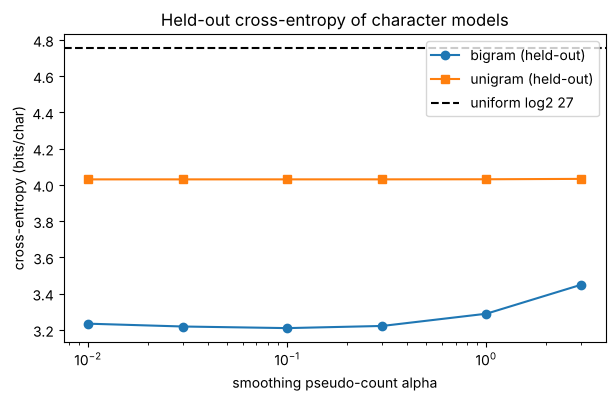

best alpha for the bigram model on held-out text: 0.1  (3.2100 bits/char)

most surprising bigrams in the held-out text (bits): [('8.8', 'ty'), ('8.4', 'su'), ('8.4', 'rt'), ('7.7', 'ew'), ('7.7', ' v')]
sampled from the bigram model: t ir s ts ryd themr he piraithay wjypqf theitoms s thalcoug het thug sicsaivingvecenlkzvmince ile ocecceczresthete oft as


In [19]:
train_text = (
    "The market opens early on Saturday mornings, long before the first tram rattles across the bridge. "
    "Farmers from the hills arrive with crates of apples and pears, and the baker sets out loaves that are "
    "still warm from the oven. By eight the square is full of people carrying baskets, comparing prices, and "
    "stopping to talk with neighbours they have not seen all week. Children chase each other between the "
    "stalls while their parents argue gently about whether the household really needs another jar of honey. "
    "Near the fountain an old man sells used books from a folding table; he claims to have read every one of "
    "them, and nobody has ever caught him out. When it rains the whole scene moves under the arches of the "
    "town hall, and the voices echo until the market sounds twice as busy as it is. The cheese seller keeps a "
    "small notebook in which she records what sold and what did not, and over the years the notebook has "
    "become a better forecast of the weather than the radio: when the soft cheeses sell out, the afternoon "
    "will be warm. Towards noon the crowd thins, the farmers pack what remains into their vans, and the "
    "sweepers arrive with their wide brooms. By one o'clock the square belongs again to the pigeons, who "
    "inspect the cobblestones for crumbs with the patience of accountants. The library on the corner opens at "
    "two. Its reading room has tall windows and a clock that has been seven minutes fast for as long as anyone "
    "can remember, so that readers who trust it are always early for dinner. The librarian knows which "
    "regulars want the newspaper and which want the chess books, and she places them on the right tables "
    "before the doors open. On winter afternoons the radiators knock and hiss, and the room fills with the "
    "smell of wet coats drying. Students come here to work because the silence is kinder than the silence at "
    "home; it is a silence shared with other people, which is a different thing entirely. In the evening the "
    "cafes along the river put out their lamps, and the smell of coffee and fried onions drifts across the "
    "water. A small band plays on the terrace of the oldest cafe, mostly songs that everybody knows, so that "
    "the audience hums along without quite meaning to. The river itself moves slowly here, carrying leaves "
    "and the occasional lost football towards the sea, and couples lean on the railing to watch it go as if "
    "it were a performance arranged for them. The bridge was rebuilt after the war with stone from the old "
    "quarry, and the masons left their marks on the underside where only the boatmen can see them. Every "
    "spring the river rises to the second step of the landing stage and the children bet on whether it will "
    "reach the third; it has done so twice in living memory, and both times the band played on."
)

heldout_text = (
    "On Sunday the town is quieter. The bells of the two churches disagree about the time by a minute or so, "
    "and for that minute the whole valley rings. Families walk up the hill to the ruined castle, where the "
    "view takes in the river, the bridge, the market square and the roofs of the old quarter, and where the "
    "wind is strong enough to steal a hat. The cafe at the top sells hot chocolate and postcards that nobody "
    "writes any more. In the afternoon the football pitch below the castle fills with the sound of a match "
    "that matters enormously to the twenty people watching it. By evening the lamps along the river are lit "
    "again, the band has packed up its instruments, and the town settles into the long quiet that lasts until "
    "the first tram on Monday."
)


import re

ALPHABET = "abcdefghijklmnopqrstuvwxyz "
V = len(ALPHABET)
idx = {c: i for i, c in enumerate(ALPHABET)}

def preprocess(text):
    text = re.sub(r"[^a-z ]", " ", text.lower())      # keep letters and spaces only
    return re.sub(r" +", " ", text).strip()

train = preprocess(train_text); heldout = preprocess(heldout_text)
print(f"training characters: {len(train)},  held-out characters: {len(heldout)},  alphabet size V = {V}")

# --- models: uniform, unigram, bigram (add-alpha smoothing) ---------------------------------
def unigram_logprobs(text, alpha):
    counts = np.zeros(V)
    for c in text:
        counts[idx[c]] += 1
    return np.log2((counts + alpha) / (counts.sum() + alpha * V))

def bigram_logprobs(text, alpha):
    counts = np.zeros((V, V))                         # counts[prev, next]
    for a, b in zip(text[:-1], text[1:]):
        counts[idx[a], idx[b]] += 1
    probs = (counts + alpha) / (counts.sum(axis=1, keepdims=True) + alpha * V)
    return np.log2(probs)

def cross_entropy_unigram(logp, text):
    return -np.mean([logp[idx[c]] for c in text])

def cross_entropy_bigram(logp2, logp1, text):
    # the first character is scored with the unigram model, the rest with the bigram model
    ll = [logp1[idx[text[0]]]] + [logp2[idx[a], idx[b]] for a, b in zip(text[:-1], text[1:])]
    return -np.mean(ll)

alpha = 0.5
lp1 = unigram_logprobs(train, alpha); lp2 = bigram_logprobs(train, alpha)
results = {
    "uniform": np.log2(V),
    "unigram": cross_entropy_unigram(lp1, heldout),
    "bigram":  cross_entropy_bigram(lp2, lp1, heldout),
}
print(f"\nheld-out cross-entropy (alpha = {alpha}):")
for name, ce in results.items():
    print(f"  {name:8s} {ce:.4f} bits/char   perplexity {2**ce:6.2f}   compression vs 8-bit ASCII: {100 * ce / 8:.1f}%")
print(f"\ntraining-set cross-entropy (optimistic): unigram {cross_entropy_unigram(lp1, train):.4f}, bigram {cross_entropy_bigram(lp2, lp1, train):.4f} bits/char")

# --- smoothing sweep --------------------------------------------------------------------------
alphas = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
ce_bi = [cross_entropy_bigram(bigram_logprobs(train, a), unigram_logprobs(train, a), heldout) for a in alphas]
ce_uni = [cross_entropy_unigram(unigram_logprobs(train, a), heldout) for a in alphas]
plt.semilogx(alphas, ce_bi, "o-", label="bigram (held-out)")
plt.semilogx(alphas, ce_uni, "s-", label="unigram (held-out)")
plt.axhline(np.log2(V), color="k", ls="--", label="uniform log2 27")
plt.xlabel("smoothing pseudo-count alpha"); plt.ylabel("cross-entropy (bits/char)")
plt.title("Held-out cross-entropy of character models"); plt.legend(); plt.show()
best_a = alphas[int(np.argmin(ce_bi))]
print(f"best alpha for the bigram model on held-out text: {best_a}  ({min(ce_bi):.4f} bits/char)")

# --- what the models know: most surprising held-out characters, and a sample --------------------
surprises = sorted(((-lp2[idx[a], idx[b]], a + b) for a, b in zip(heldout[:-1], heldout[1:])), reverse=True)[:5]
print("\nmost surprising bigrams in the held-out text (bits):", [(f"{s:.1f}", pair) for s, pair in surprises])
rng = np.random.default_rng(14)
probs2 = 2 ** lp2
c = idx["t"]; sample = ["t"]
for _ in range(120):
    c = rng.choice(V, p=probs2[c]); sample.append(ALPHABET[c])
print("sampled from the bigram model:", "".join(sample))

## Score

In [20]:
summary()


Score: 56/56 checks passed  🎉
